# Correcting performance claims for multiple testing

A one-sided test turns every per-period Sharpe estimate into a probability under the zero-Sharpe null:

$$
z_j=\widehat{SR}_j\sqrt{T},
\qquad
p_j=1-\Phi(z_j).
$$

Here, $\widehat{SR}_j$ is the Sharpe ratio for trial $j$, $T$ is its number of returns, $z_j$ is the standardized statistic under the independent normal null, $\Phi$ is the standard-normal distribution function, and $p_j$ is the one-sided p-value for a positive Sharpe ratio.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("20_sharpe_multiple_testing");
using CSV, TOML, Printf
prefix = "multiple"
source_path = dataset_path("fred_sp500")
raw = CSV.read(source_path,DataFrame;missingstring=["","."])
dropmissing!(raw,:SP500)
sort!(raw,:observation_date)
price_dates,prices = Date.(raw.observation_date),Float64.(raw.SP500)
returns = vcat(NaN,diff(log.(prices)))

function exponential_average(values,span)
    alpha = 2/(span+1)
    result = copy(values)
    for index in 2:length(values)
        result[index] = (1-alpha)*result[index-1]+alpha*values[index]
    end
    result[1:span-1] .= NaN
    return result
end

columns,catalog_records = Vector{Float64}[],NamedTuple[]
for fast in [3,5,10,20], slow in [30,60,120,240]
    fast_average,slow_average = exponential_average(prices,fast),exponential_average(prices,slow)
    signal = sign.(fast_average.-slow_average)
    for index in 2:length(signal)
        signal[index]==0 && (signal[index]=signal[index-1])
    end
    position = vcat(NaN,signal[1:end-1])
    for (orientation,multiplier) in [("Trend",1.),("Reversal",-1.)]
        name = orientation*" "*string(fast)*"/"*string(slow)
        push!(columns,multiplier.*position.*returns)
        push!(catalog_records,(trial=length(catalog_records)+1,rule=orientation,fast=fast,slow=slow,name=name))
    end
end
complete = findall(vec(all(isfinite,reduce(hcat,columns);dims=2)))
performances = reduce(hcat,columns)[complete,:]
dates = price_dates[complete]
strategy_catalog = DataFrame(catalog_records)
rename!(strategy_catalog,["Trial","Rule","Fast span","Slow span","Name"])
names_trials = strategy_catalog.Name
@assert size(performances)==(2090,32)
performance_frame = DataFrame(performances,names_trials)
insertcols!(performance_frame,1,:date=>dates)
save_data(performance_frame,paths,prefix*"_performances")
save_data(DataFrame(date=price_dates,price=prices),paths,prefix*"_prices")
violet = "#C084FC"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter20-"*replace(name,"_"=>"-"))

using Distributions: Normal,quantile
using RiskLabAI.Backtest: probabilistic_sharpe_ratio,benchmark_sharpe_ratio,lplz_sharpe_inference,newey_west_automatic_lag,newey_west_long_run_variance,sharpe_ratio_influence_function,benjamini_hochberg_yekutieli_adjusted_p_values,haircut_sharpe_ratios,holm_adjusted_p_values,sharpe_ratio_p_values,expected_max_sharpe_ratio,estimated_sharpe_ratio_z_statistics,strategy_type1_error_probability,strategy_type2_error_probability,theta_for_type2_error,sharpe_difference_test

function period_sharpe(values)
    deviation = std(values)
    return deviation>0 ? mean(values)/deviation : 0.
end

function return_moments(values)
    n = length(values)
    centered = values.-mean(values)
    second,third,fourth = mean(centered.^2),mean(centered.^3),mean(centered.^4)
    skewness = sqrt(n*(n-1))/(n-2)*third/second^1.5
    kurtosis = (n-1)/((n-2)*(n-3))*((n+1)*(fourth/second^2-3)+6)+3
    return skewness,kurtosis
end

psr(sharpe,benchmark,n,skewness=0.,kurtosis=3.;return_test_statistic=false) = probabilistic_sharpe_ratio(sharpe,benchmark,n;skewness_of_returns=skewness,kurtosis_of_returns=kurtosis,return_test_statistic)
opposite_name(name) = startswith(name,"Trend") ? replace(name,"Trend"=>"Reversal") : replace(name,"Reversal"=>"Trend")
trial_sharpes = period_sharpe.(eachcol(performances))
annual_sharpes = trial_sharpes.*sqrt(252.)
trial_mean,trial_spread = mean(trial_sharpes),std(trial_sharpes;corrected=false)
observation_count,trial_count = size(performances)

function read_primitive(name)
    root = joinpath("..","data","chapter20_random_inputs")
    manifest_path = joinpath(root,"inputs.toml")
    metadata = TOML.parsefile(manifest_path)["files"][name*".bin"]
    path = joinpath(root,name*".bin")
    values = reinterpret(Float64,ltoh.(reinterpret(UInt64,read(path))))
    @assert length(values)==metadata["values"]
    return reshape(values,Tuple(metadata["shape"]))
end

function ar1_values(innovations,persistence;scale=.01)
    values = zeros(size(innovations))
    for index in 2:size(values,1)
        values[index,:] = persistence.*values[index-1,:].+scale.*innovations[index,:]
    end
    return values
end


ar1_values (generic function with 1 method)

## Public Trial Family Corrections

Holm's ordered correction increases each raw p-value according to the number of hypotheses that remain:

$$
p_{(i)}^{Holm}=\min\!\left\{1,\max_{1\leq j\leq i}(M-j+1)p_{(j)}\right\}.
$$

Here, $M$ is the number of tested trials, $p_{(j)}$ is the $j$th smallest raw p-value, $i$ is its ordered position, and $p_{(i)}^{Holm}$ is the adjusted p-value that controls the chance of at least one false rejection across the family.

The Benjamini-Hochberg-Yekutieli correction uses a harmonic dependence factor and works backward through the ordered p-values:

$$
c_M=\sum_{j=1}^{M}\frac{1}{j},
\qquad
p_{(i)}^{BHY}=\min\!\left\{1,\min_{i\leq j\leq M}\frac{c_M M}{j}p_{(j)}\right\}.
$$

Here, $c_M$ is the harmonic dependence factor, $M$ is the family size, $p_{(j)}$ is the $j$th ordered raw p-value, and $p_{(i)}^{BHY}$ is the adjusted p-value that controls the expected fraction of false discoveries under arbitrary dependence.

An adjusted p-value can be expressed on the same scale as the original per-period Sharpe ratio:

$$
\widehat{SR}_{j,adj}=\frac{\Phi^{-1}(1-p_{j,adj})}{\sqrt{T}}.
$$

Here, $p_{j,adj}$ is the adjusted p-value for trial $j$, $\Phi^{-1}$ is the standard-normal quantile function, $T$ is the number of returns, and $\widehat{SR}_{j,adj}$ is the Sharpe ratio implied by that adjusted probability.

Row,Trial,Name,Annual Sharpe,Raw p-value,Holm p-value,BHY p-value,Holm haircut Sharpe,BHY haircut Sharpe,Holm discovery,BHY discovery
,Int64,String,Float64,Float64,Float64,Float64,Float64,Float64,Bool,Bool
1,1,Trend 3/30,0.368432,0.144336,1.0,1.0,-Inf,-Inf,false,false
2,2,Reversal 3/30,-0.368432,0.855664,1.0,1.0,-Inf,-Inf,false,false
3,3,Trend 3/60,0.252547,0.233521,1.0,1.0,-Inf,-Inf,false,false
4,4,Reversal 3/60,-0.252547,0.766479,1.0,1.0,-Inf,-Inf,false,false
5,5,Trend 3/120,0.290021,0.201796,1.0,1.0,-Inf,-Inf,false,false
6,6,Reversal 3/120,-0.290021,0.798204,1.0,1.0,-Inf,-Inf,false,false
7,7,Trend 3/240,0.19922,0.283076,1.0,1.0,-Inf,-Inf,false,false
8,8,Reversal 3/240,-0.19922,0.716924,1.0,1.0,-Inf,-Inf,false,false
9,9,Trend 5/30,0.448622,0.0981834,1.0,1.0,-Inf,-Inf,false,false


Row,Trial,Name,Annual Sharpe,Raw p-value,Holm p-value,BHY p-value,Holm haircut Sharpe,BHY haircut Sharpe,Holm discovery,BHY discovery
,Int64,String,Float64,Float64,Float64,Float64,Float64,Float64,Bool,Bool
1,9,Trend 5/30,0.448622,0.0981834,1.0,1.0,-Inf,-Inf,false,false
2,27,Trend 20/60,0.413375,0.116931,1.0,1.0,-Inf,-Inf,false,false
3,13,Trend 5/120,0.370794,0.142797,1.0,1.0,-Inf,-Inf,false,false
4,1,Trend 3/30,0.368432,0.144336,1.0,1.0,-Inf,-Inf,false,false
5,21,Trend 10/120,0.356375,0.152372,1.0,1.0,-Inf,-Inf,false,false
6,17,Trend 10/30,0.342441,0.162021,1.0,1.0,-Inf,-Inf,false,false
7,5,Trend 3/120,0.290021,0.201796,1.0,1.0,-Inf,-Inf,false,false
8,3,Trend 3/60,0.252547,0.233521,1.0,1.0,-Inf,-Inf,false,false
9,15,Trend 5/240,0.250915,0.234962,1.0,1.0,-Inf,-Inf,false,false


Row,Procedure,Error target,Discoveries at five percent,Smallest p-value
,String,String,Int64,Float64
1,No family correction,Individual one-sided error,0,0.0981834
2,Holm,Chance of any false discovery,0,1.0
3,BHY,Expected false share among discoveries,0,1.0


Row,Quantity,Value
,String,Float64
1,Trials,32.0
2,Pairwise correlations,496.0
3,Mean correlation,-0.0322581
4,Mean absolute correlation,0.719366
5,Median absolute correlation,0.750579
6,Largest absolute correlation,1.0


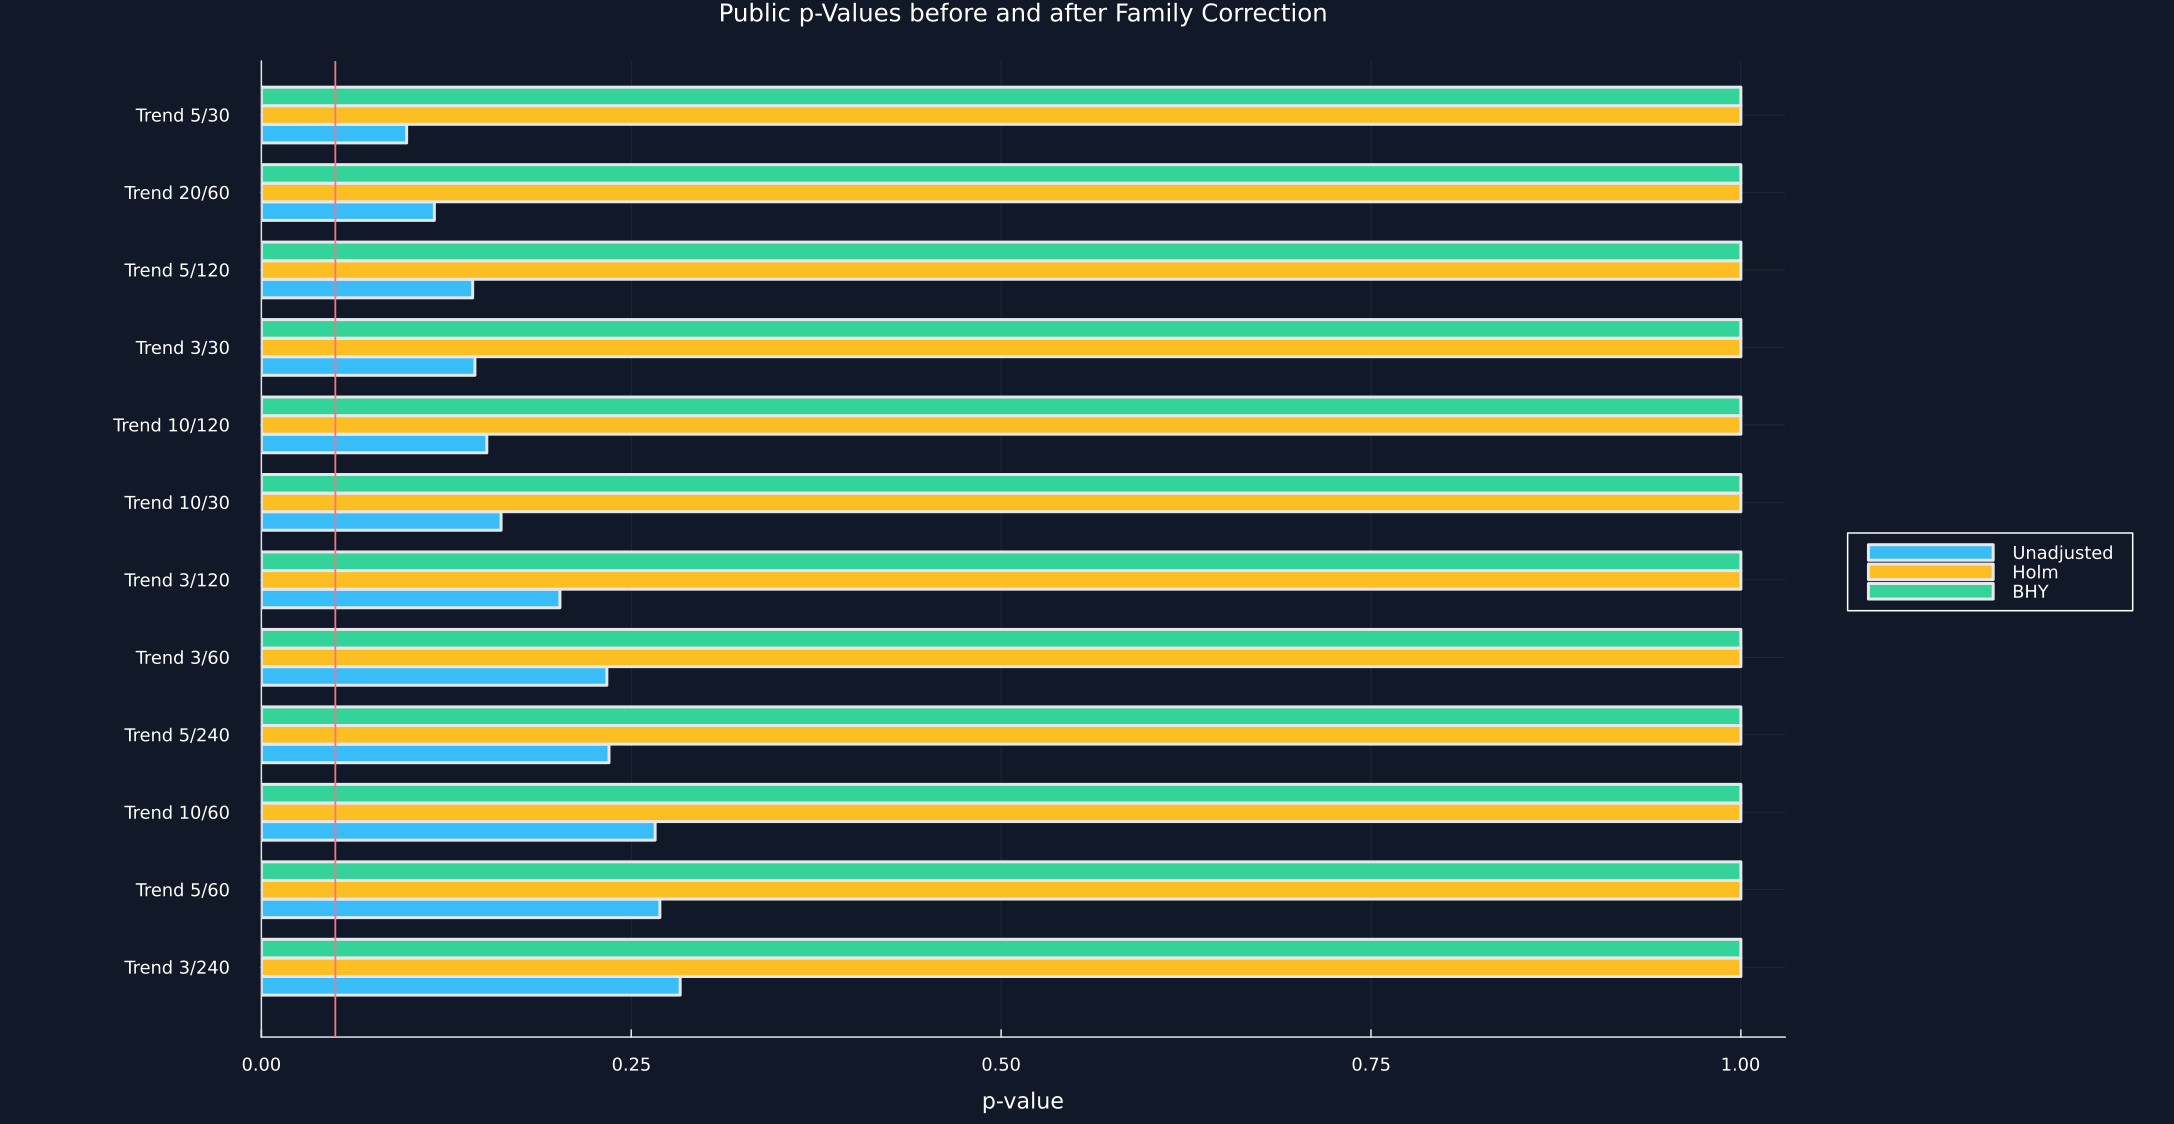

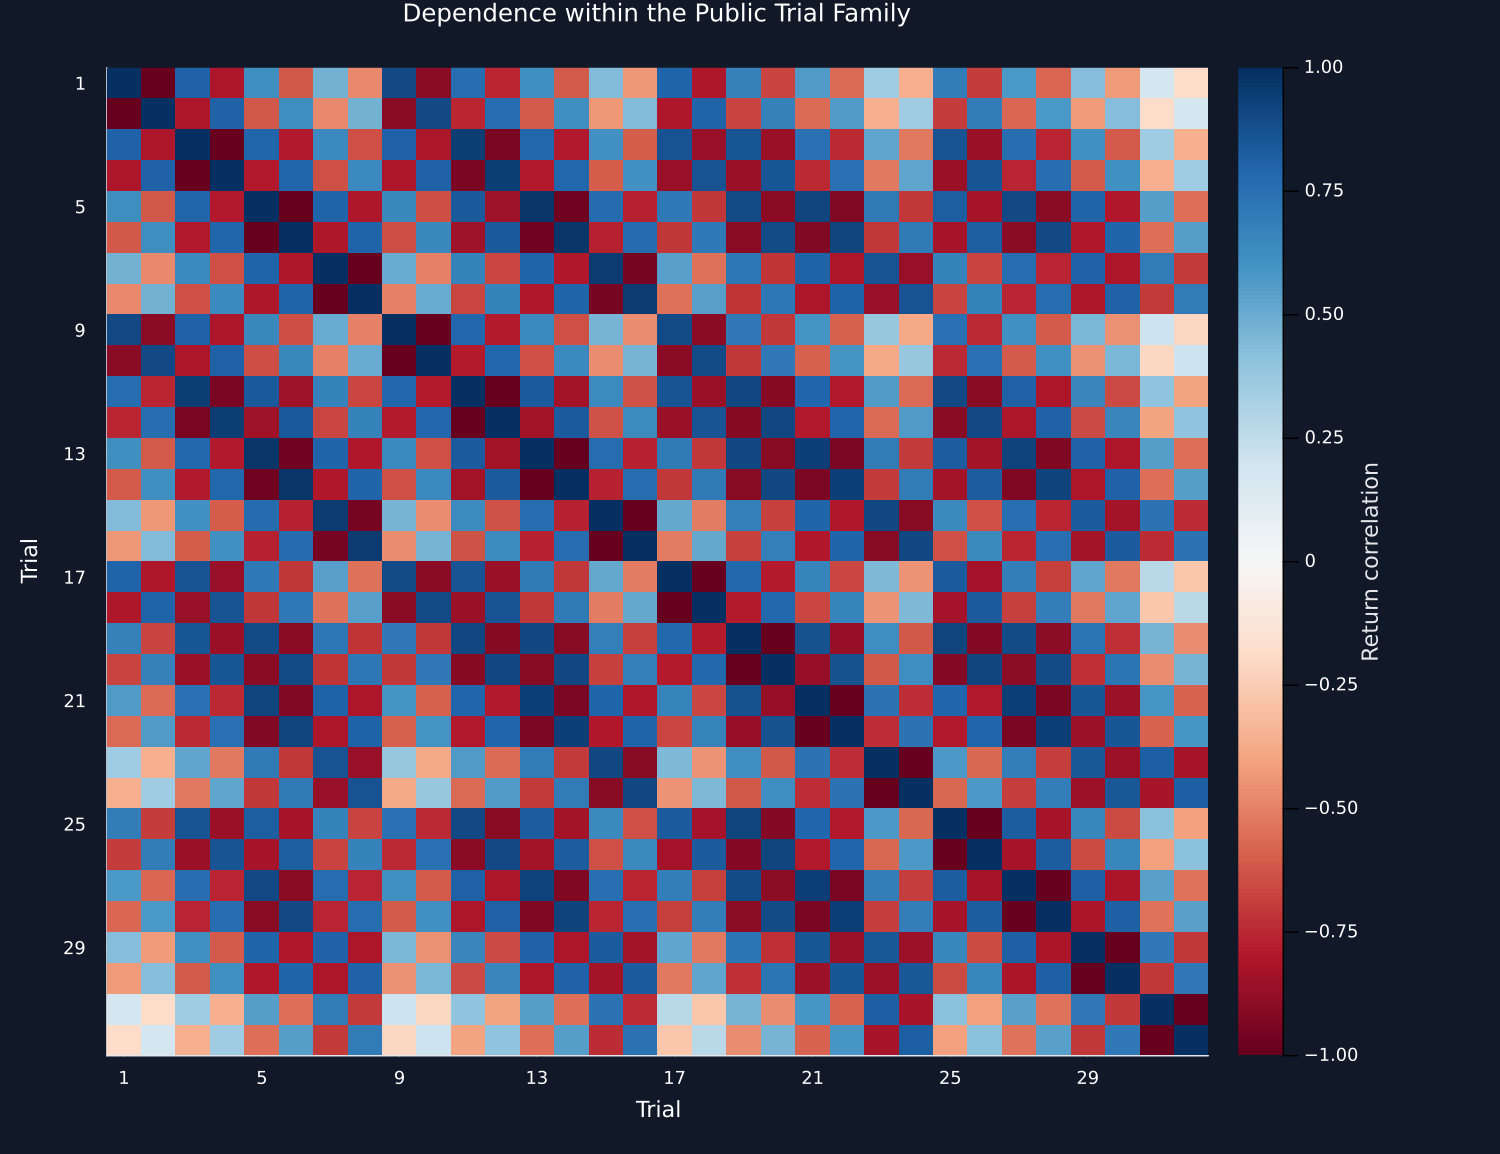

In [2]:
holm_public = haircut_sharpe_ratios(trial_sharpes,observation_count;method="holm")
bhy_public = haircut_sharpe_ratios(trial_sharpes,observation_count;method="bhy")
public_multiple_testing = DataFrame("Trial"=>collect(1:32),"Name"=>names_trials,"Annual Sharpe"=>annual_sharpes,"Raw p-value"=>holm_public.p_values,"Holm p-value"=>holm_public.adjusted_p_values,"BHY p-value"=>bhy_public.adjusted_p_values,"Holm haircut Sharpe"=>holm_public.haircut_sharpe_ratios.*sqrt(252.),"BHY haircut Sharpe"=>bhy_public.haircut_sharpe_ratios.*sqrt(252.),"Holm discovery"=>holm_public.significant,"BHY discovery"=>bhy_public.significant)
leading_public_multiple_testing = first(sort(public_multiple_testing,["Annual Sharpe","Trial"];rev=[true,false]),12)
procedure_summary = DataFrame("Procedure"=>["No family correction","Holm","BHY"],"Error target"=>["Individual one-sided error","Chance of any false discovery","Expected false share among discoveries"],"Discoveries at five percent"=>[sum(holm_public.p_values.<.05),sum(holm_public.significant),sum(bhy_public.significant)],"Smallest p-value"=>[minimum(holm_public.p_values),minimum(holm_public.adjusted_p_values),minimum(bhy_public.adjusted_p_values)])
correlations = cor(performances)
upper_values = [correlations[row,column] for row in 1:31 for column in row+1:32]
trial_dependence_summary = DataFrame("Quantity"=>["Trials","Pairwise correlations","Mean correlation","Mean absolute correlation","Median absolute correlation","Largest absolute correlation"],"Value"=>[32,length(upper_values),mean(upper_values),mean(abs.(upper_values)),median(abs.(upper_values)),maximum(abs.(upper_values))])
table(public_multiple_testing,"public_multiple_testing","Multiple-testing results for every public trial.")
table(leading_public_multiple_testing,"leading_public_multiple_testing","Sharpe haircuts for the twelve largest public Sharpe estimates.")
table(procedure_summary,"procedure_summary","Discoveries in the public trial family under three error rules.")
table(trial_dependence_summary,"trial_dependence_summary","Dependence among the public strategy trials.")
ordered = sort(leading_public_multiple_testing,"Annual Sharpe")
figure = plot(;yticks=(1:12,ordered.Name),xlims=(0,1.03),xlabel="p-value",title="Public p-Values before and after Family Correction",legend=:outerright,size=(1450,750),left_margin=18Plots.mm)
for (offset,column,color,label) in [(-.24,"Raw p-value",palette.cyan,"Unadjusted"),(0.,"Holm p-value",palette.amber,"Holm"),(.24,"BHY p-value",palette.green,"BHY")]
    bar!(figure,collect(1:12).+offset,ordered[!,column];orientation=:h,bar_width=.24,color,label)
end
vline!(figure,[.05];color=palette.rose,label="",linewidth=1.2)
save_figure(figure,paths,"public_haircuts")
save_data(DataFrame(correlations,:auto),paths,"trial_correlation")
figure = heatmap(1:32,1:32,correlations;color=:RdBu,clims=(-1,1),yflip=true,xticks=1:4:32,yticks=1:4:32,colorbar_title="Return correlation",xlabel="Trial",ylabel="Trial",title="Dependence within the Public Trial Family",size=(1000,770),right_margin=18Plots.mm,grid=false)
save_figure(figure,paths,"trial_correlation")


## Preliminary Planted-Edge Reproduction

Row,Trial,Known edge,Raw Sharpe,Holm p-value,Holm haircut Sharpe,Holm discovery,BHY p-value,BHY haircut Sharpe,BHY discovery
,Int64,Bool,Float64,Float64,Float64,Bool,Float64,Float64,Bool
1,2,true,0.389464,0.000198684,0.323323,true,0.000714814,0.291078,true
2,1,true,0.355244,0.00094642,0.283588,true,0.00179209,0.265884,true
3,0,true,0.24572,0.0639742,0.138961,false,0.0852453,0.125121,false
4,4,false,0.155232,0.756839,-0.0635512,false,0.800855,-0.0771084,false
5,17,false,0.13873,1.0,-Inf,false,0.901942,-0.118006,false
6,10,false,0.131276,1.0,-Inf,false,0.901942,-0.118006,false
7,13,false,0.109598,1.0,-Inf,false,1.0,-Inf,false
8,3,false,0.0839056,1.0,-Inf,false,1.0,-Inf,false


Row,Quantity,Value
,String,Float64
1,Returns,120.0
2,Trials,20.0
3,Known positive trials,3.0
4,Largest raw Sharpe,0.389464
5,Second-largest raw Sharpe,0.355244
6,Expected maximum for one trial,0.0
7,Expected maximum for five trials,0.158703
8,Expected maximum for twenty trials,0.252934
9,Holm discoveries,2.0


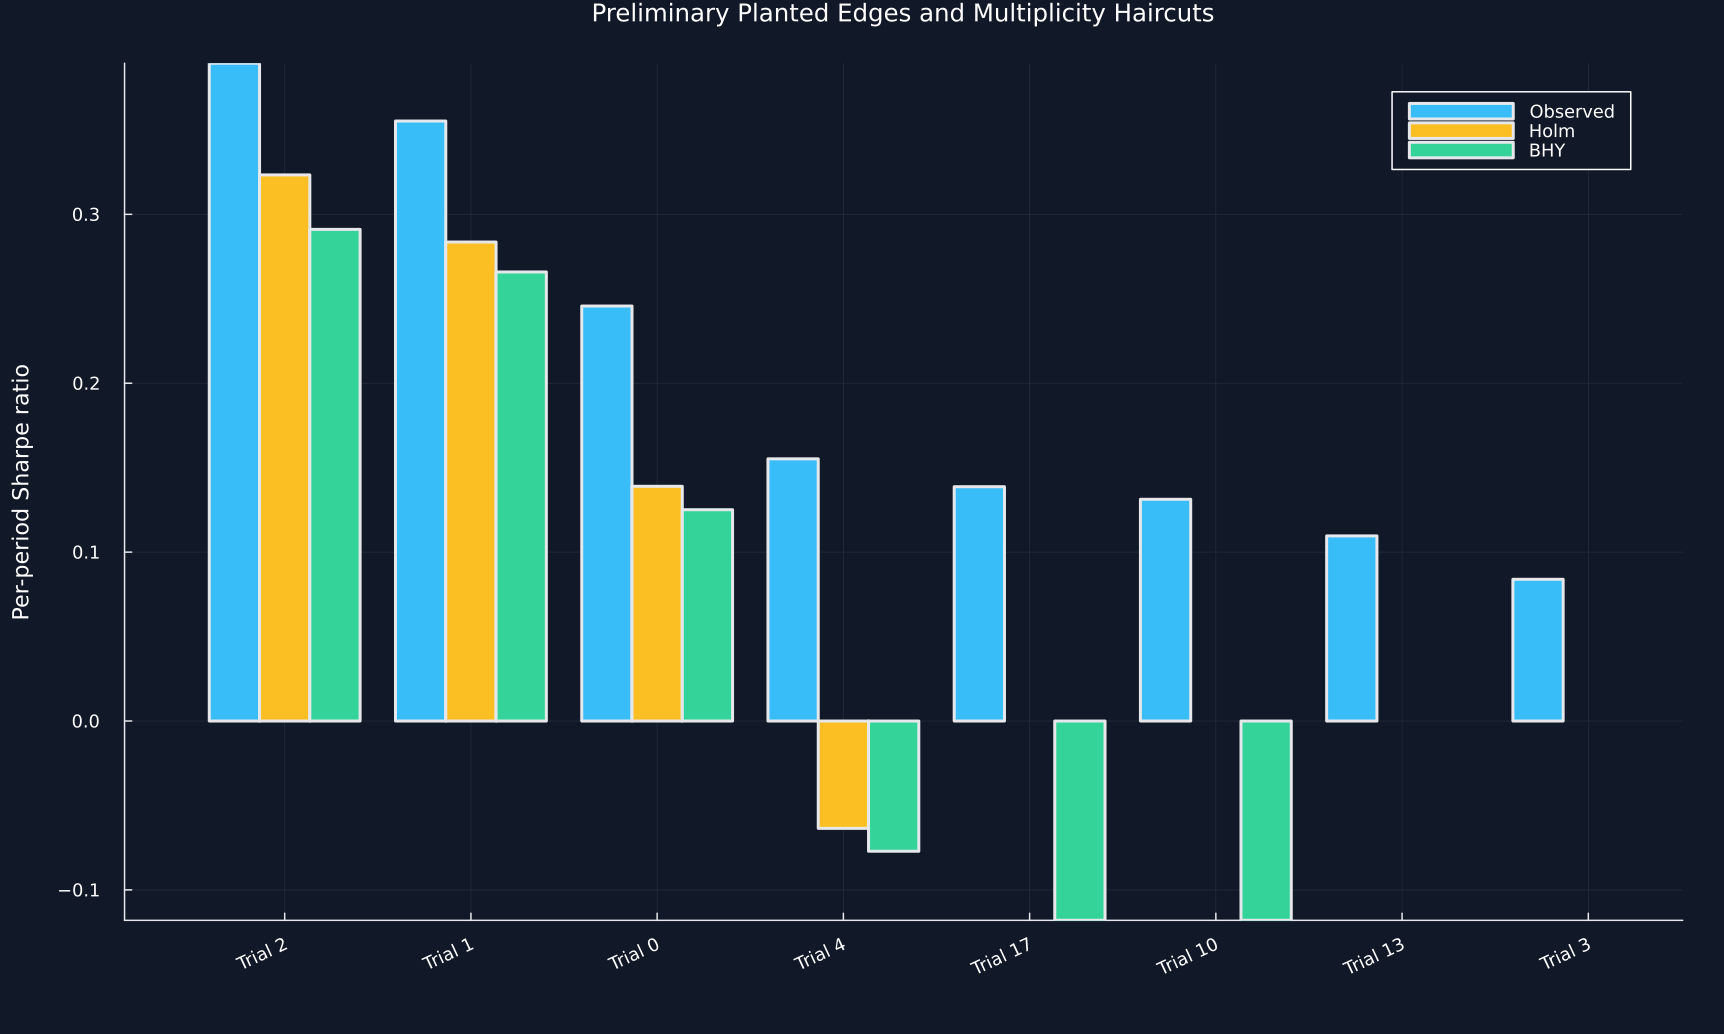

In [3]:
preliminary_returns = read_primitive("preliminary_planted").*0.04
preliminary_returns[:,1:3] .+= .012
preliminary_sharpes = period_sharpe.(eachcol(preliminary_returns))
preliminary_order = sortperm(preliminary_sharpes;rev=true)
preliminary_holm = haircut_sharpe_ratios(preliminary_sharpes,120;method="holm")
preliminary_bhy = haircut_sharpe_ratios(preliminary_sharpes,120;method="bhy")
chosen = preliminary_order[1:8]
preliminary_planted_edges = DataFrame("Trial"=>chosen.-1,"Known edge"=>chosen.<=3,"Raw Sharpe"=>preliminary_sharpes[chosen],"Holm p-value"=>preliminary_holm.adjusted_p_values[chosen],"Holm haircut Sharpe"=>preliminary_holm.haircut_sharpe_ratios[chosen],"Holm discovery"=>preliminary_holm.significant[chosen],"BHY p-value"=>preliminary_bhy.adjusted_p_values[chosen],"BHY haircut Sharpe"=>preliminary_bhy.haircut_sharpe_ratios[chosen],"BHY discovery"=>preliminary_bhy.significant[chosen])
preliminary_spread = std(preliminary_sharpes;corrected=false)
preliminary_haircut_summary = DataFrame("Quantity"=>["Returns","Trials","Known positive trials","Largest raw Sharpe","Second-largest raw Sharpe","Expected maximum for one trial","Expected maximum for five trials","Expected maximum for twenty trials","Holm discoveries","BHY discoveries"],"Value"=>[120,20,3,preliminary_sharpes[chosen[1]],preliminary_sharpes[chosen[2]],expected_max_sharpe_ratio(1,0.,preliminary_spread),expected_max_sharpe_ratio(5,0.,preliminary_spread),expected_max_sharpe_ratio(20,0.,preliminary_spread),sum(preliminary_holm.significant),sum(preliminary_bhy.significant)])
table(preliminary_planted_edges,"preliminary_planted_edges","The eight largest Sharpe ratios in the preliminary planted-edge experiment; trial labels retain their original zero-based values.")
table(preliminary_haircut_summary,"preliminary_haircut_summary","Summary of the preliminary planted-edge and haircut calculations.")
save_data(DataFrame(trial=collect(0:19),sharpe=preliminary_sharpes,raw_p=preliminary_holm.p_values,holm=preliminary_holm.adjusted_p_values,bhy=preliminary_bhy.adjusted_p_values,holm_sharpe=preliminary_holm.haircut_sharpe_ratios,bhy_sharpe=preliminary_bhy.haircut_sharpe_ratios),paths,"preliminary_planted_all")
figure = plot(;xticks=(1:8,["Trial "*string(index) for index in preliminary_planted_edges.Trial]),xrotation=25,ylabel="Per-period Sharpe ratio",title="Preliminary Planted Edges and Multiplicity Haircuts",legend=:topright,size=(1150,690),bottom_margin=10Plots.mm)
for (offset,column,color,label) in [(-.27,"Raw Sharpe",palette.cyan,"Observed"),(0.,"Holm haircut Sharpe",palette.amber,"Holm"),(.27,"BHY haircut Sharpe",palette.green,"BHY")]
    values = preliminary_planted_edges[!,column]
    bar!(figure,collect(1:8).+offset,ifelse.(isfinite.(values),values,NaN);bar_width=.27,color,label)
end
save_figure(figure,paths,"preliminary_haircuts")


Without a family correction, independent tests make at least one false rejection with probability:

$$
\alpha_M=1-(1-\alpha)^M.
$$

Here, $\alpha$ is the false-positive probability for one test, $M$ is the number of independent tests, and $\alpha_M$ is the probability of at least one false positive across the family.

## Understanding the cost of error control

Row,Tests,Individual error rate,Family error rate
,Int64,Float64,Float64
1,1,0.05,0.05
2,5,0.05,0.226219
3,10,0.05,0.401263
4,20,0.05,0.641514
5,50,0.05,0.923055
6,100,0.05,0.994079


Row,Returns,Trials,True positive trials,Procedure,Family false-positive rate,False discovery rate,True discovery rate,Repetitions
,Int64,Int64,Int64,String,Float64,Float64,Float64,Int64
1,120,5,3,Unadjusted,0.075,0.0279167,0.711667,200
2,120,5,3,Holm,0.045,0.0233333,0.485,200
3,120,5,3,BHY,0.02,0.0075,0.418333,200
4,120,20,3,Unadjusted,0.595,0.256333,0.706667,200
5,120,20,3,Holm,0.045,0.03,0.31,200
6,120,20,3,BHY,0.03,0.015,0.218333,200
7,120,50,3,Unadjusted,0.89,0.488147,0.711667,200
8,120,50,3,Holm,0.055,0.0425,0.23,200
9,120,50,3,BHY,0.025,0.0158333,0.14,200


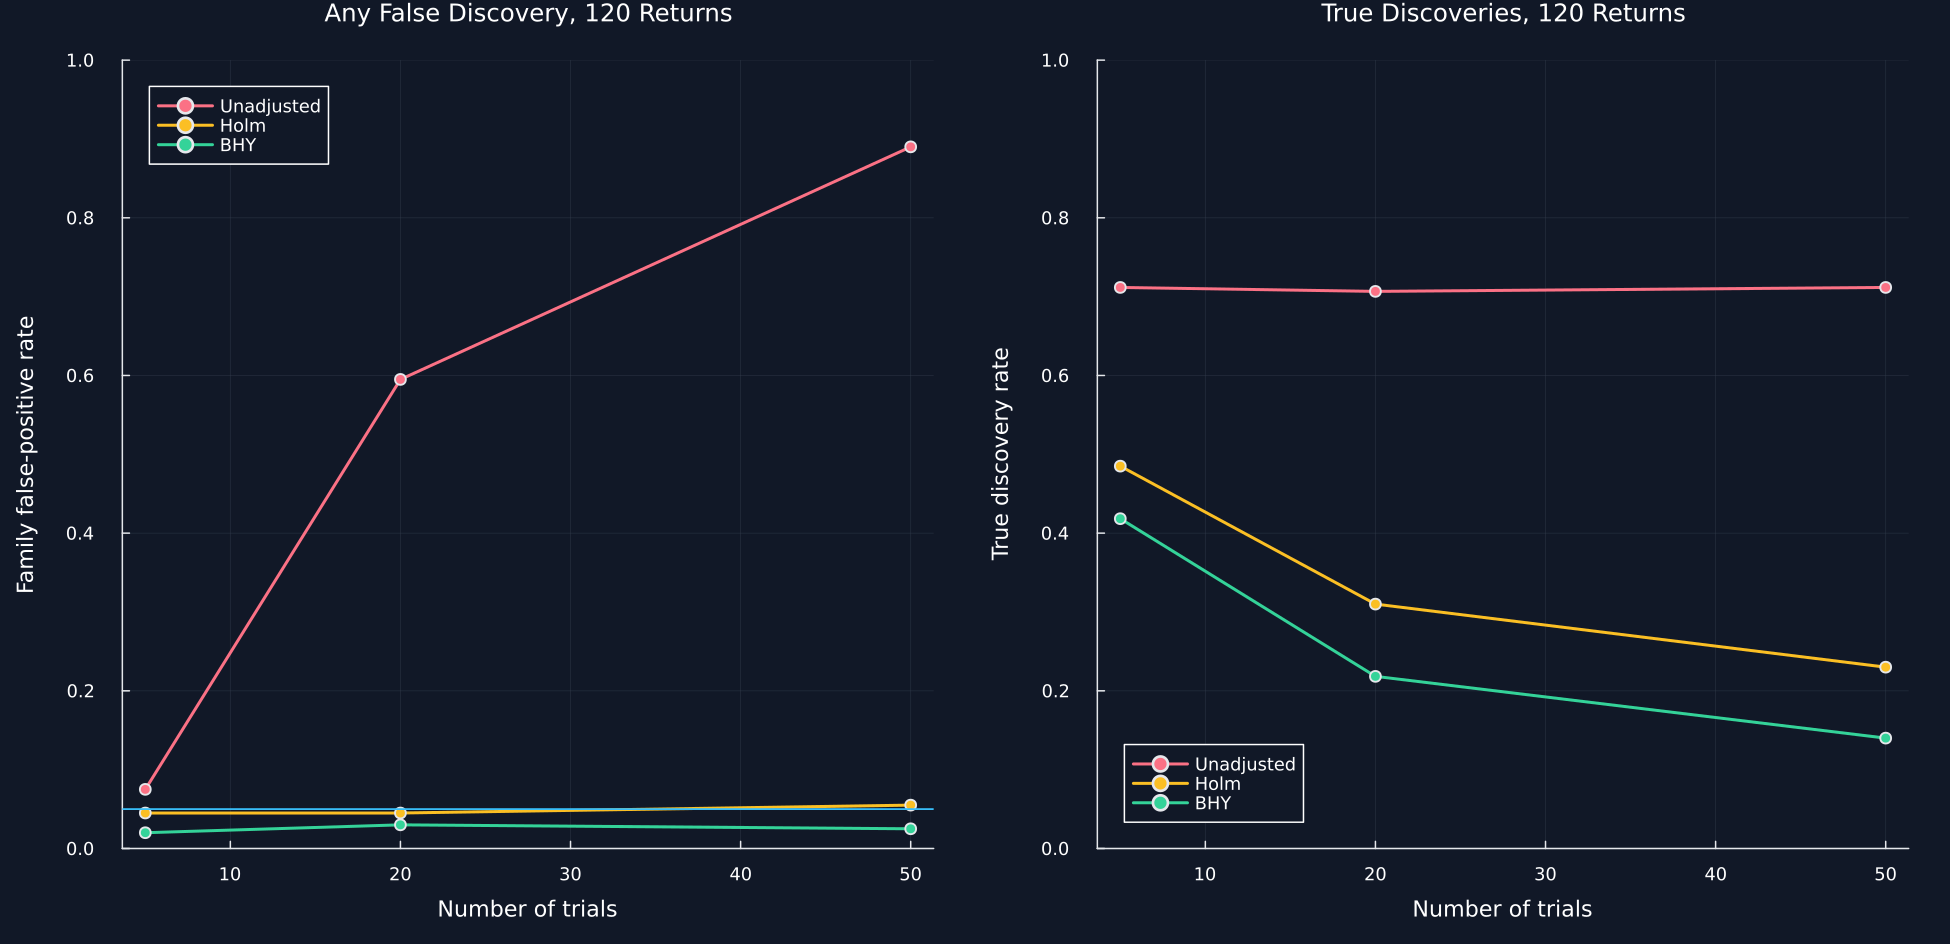

In [4]:
tests = [1,5,10,20,50,100]
type1_error_growth = DataFrame("Tests"=>tests,"Individual error rate"=>fill(.05,6),"Family error rate"=>1 .- 0.95 .^ tests)
simulation_rows,decision_rows = NamedTuple[],NamedTuple[]
for number_of_returns in [120,500], number_of_trials in [5,20,50]
    innovations = read_primitive("family_"*string(number_of_returns)*"_"*string(number_of_trials))
    family_records = Dict(name=>NamedTuple[] for name in ["Unadjusted","Holm","BHY"])
    for repetition in 1:200
        values = innovations[:,:,repetition].*0.04
        values[:,1:3] .+= .008
        sharpes = vec(mean(values;dims=1))./vec(std(values;dims=1))
        raw = sharpe_ratio_p_values(sharpes,number_of_returns)
        holm,bhy = holm_adjusted_p_values(raw),benjamini_hochberg_yekutieli_adjusted_p_values(raw)
        for (method,pvalues) in [("Unadjusted",raw),("Holm",holm),("BHY",bhy)]
            selected = pvalues.<.05
            false_count,discovery_count = sum(selected[4:end]),sum(selected)
            push!(family_records[method],(family=Int(false_count>0),false_share=false_count/max(discovery_count,1),true_share=mean(selected[1:3])))
        end
        for trial in 1:number_of_trials
            push!(decision_rows,(returns=number_of_returns,trials=number_of_trials,repetition=repetition,trial=trial,sharpe=sharpes[trial],raw=raw[trial],holm=holm[trial],bhy=bhy[trial]))
        end
    end
    for method in ["Unadjusted","Holm","BHY"]
        records = family_records[method]
        push!(simulation_rows,(returns=number_of_returns,trials=number_of_trials,true_trials=3,procedure=method,family=mean(row.family for row in records),false_discovery=mean(row.false_share for row in records),true_discovery=mean(row.true_share for row in records),repetitions=200))
    end
end
controlled_error_rates = DataFrame(simulation_rows)
rename!(controlled_error_rates,["Returns","Trials","True positive trials","Procedure","Family false-positive rate","False discovery rate","True discovery rate","Repetitions"])
table(type1_error_growth,"type1_error_growth","Growth in the chance of at least one false positive without correction.")
table(controlled_error_rates,"controlled_error_rates","Controlled false discoveries and power as sample and family sizes change.")
save_data(DataFrame(decision_rows),paths,"controlled_decisions")
p1 = plot(;title="Any False Discovery, 120 Returns",xlabel="Number of trials",ylabel="Family false-positive rate",ylims=(0,1),legend=:topleft)
p2 = plot(;title="True Discoveries, 120 Returns",xlabel="Number of trials",ylabel="True discovery rate",ylims=(0,1),legend=:bottomleft)
for (method,color) in [("Unadjusted",palette.rose),("Holm",palette.amber),("BHY",palette.green)]
    current = controlled_error_rates[(controlled_error_rates.Returns.==120).&(controlled_error_rates.Procedure.==method),:]
    plot!(p1,current.Trials,current[!,"Family false-positive rate"];color,label=method,marker=:circle)
    plot!(p2,current.Trials,current[!,"True discovery rate"];color,label=method,marker=:circle)
end
hline!(p1,[.05];color=palette.cyan,label="",linewidth=1.2)
save_figure(plot(p1,p2;layout=(1,2),size=(1300,630),left_margin=7Plots.mm,bottom_margin=7Plots.mm),paths,"controlled_error_rates")


## Tests

In [5]:
@assert observation_count==2090
@assert trial_count==32
@assert size(public_multiple_testing)==(32,10)
@assert size(leading_public_multiple_testing)==(12,10)
@assert size(procedure_summary)==(3,4)
@assert size(trial_dependence_summary)==(6,2)
@assert all(value->0<=value<=1,Matrix(select(public_multiple_testing,["Raw p-value","Holm p-value","BHY p-value"])))
@assert all(public_multiple_testing[!,"Holm p-value"].>=public_multiple_testing[!,"Raw p-value"].-1e-15)
@assert all(public_multiple_testing[!,"BHY p-value"].>=public_multiple_testing[!,"Raw p-value"].-1e-15)
@assert length(preliminary_sharpes)==20
@assert preliminary_order[1:3]==[3,2,1]
@assert isapprox(preliminary_sharpes[preliminary_order[1:3]],[.38946401,.35524443,.24572023];atol=1e-8)
@assert sum(preliminary_holm.significant)==2
@assert sum(preliminary_bhy.significant)==2
@assert preliminary_holm.haircut_sharpe_ratios[preliminary_order[1]]≈.3233229568994212
@assert preliminary_bhy.haircut_sharpe_ratios[preliminary_order[1]]≈.291078175760912
@assert [expected_max_sharpe_ratio(count,0.,preliminary_spread) for count in [1,5,20]]≈[0.,.1587026354881373,.252933823991373]
@assert size(type1_error_growth)==(6,3)
@assert type1_error_growth[!,"Family error rate"]≈[strategy_type1_error_probability(quantile(Normal(),.95);k=count) for count in tests]
@assert size(controlled_error_rates)==(18,8)
@assert all(value->0<=value<=1,Matrix(select(controlled_error_rates,["Family false-positive rate","False discovery rate","True discovery rate"])))
@assert all(==(200),controlled_error_rates.Repetitions)
theta = theta_for_type2_error(.2,120,.2)
@assert 0<strategy_type2_error_probability(.05,20,theta)<1
@assert isfile(joinpath(paths.figures,"public_haircuts.pdf"))
@assert isfile(joinpath(paths.figures,"trial_correlation.pdf"))
@assert isfile(joinpath(paths.figures,"preliminary_haircuts.pdf"))
@assert isfile(joinpath(paths.figures,"controlled_error_rates.pdf"))
@assert isfile(joinpath(paths.tables,"public_multiple_testing.tex"))
@assert isfile(joinpath(paths.tables,"leading_public_multiple_testing.tex"))
@assert isfile(joinpath(paths.tables,"procedure_summary.tex"))
@assert isfile(joinpath(paths.tables,"trial_dependence_summary.tex"))
@assert isfile(joinpath(paths.tables,"preliminary_planted_edges.tex"))
@assert isfile(joinpath(paths.tables,"preliminary_haircut_summary.tex"))
@assert isfile(joinpath(paths.tables,"type1_error_growth.tex"))
@assert isfile(joinpath(paths.tables,"controlled_error_rates.tex"))
